# Marker-Based Augmented Reality

---

- **Author:** Atta Ul Haleem  
- **Date:** November 15, 2026  
- **Professor:** Dr. Nicolas Rougon  
- **Course:** Basic Computer Vision  
- **Program:** M2 Virtual & Augmented Reality

In [1]:
# Pick up edits to `.py` files without restarting kernel
%load_ext autoreload
%autoreload 2

In [2]:
# Import libraries
import cv2 as cv

In [3]:
# Import modules
import config
from estimators import HomographyNotFoundError
from pipeline import (
    apply_detector,
    apply_estimator,
    apply_filter,
    apply_matcher,
    build_detector,
    build_estimator,
    build_filter,
    build_matcher,
)
from utils import (
    center_crop_to_size,
    draw_keypoints,
    draw_outline,
    grab_frame,
    load_image,
    overlay_image,
    plot_image,
    plot_image_row,
    plot_matches,
    project_corners,
    select_best_matches,
    select_inlier_matches,
    shrink_to_max_side,
    warp_image,
)

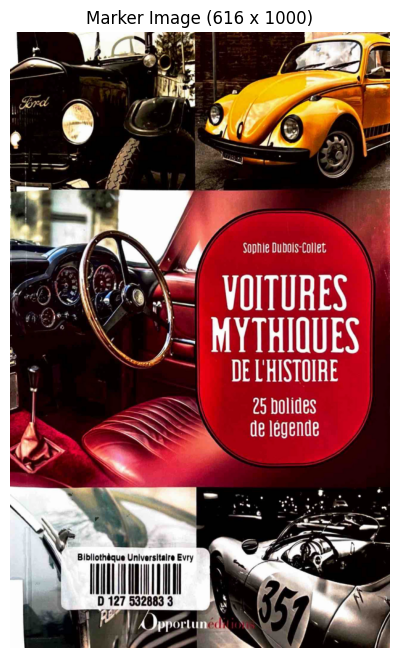

In [4]:
# Marker image
marker = load_image(config.MARKER_PATH)
marker = shrink_to_max_side(marker, config.MARKER_MAX_SIDE)
plot_image(marker, f"Marker Image ({marker.shape[1]} x {marker.shape[0]})")

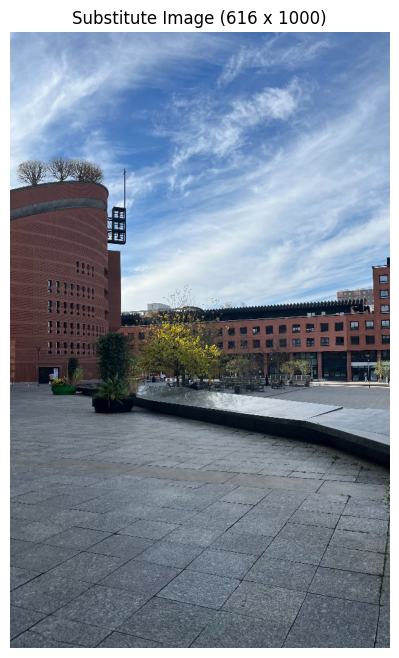

In [5]:
# Substitute image
substitute = load_image(config.SUBSTITUTE_PATH)
substitute = center_crop_to_size(substitute, marker.shape[1], marker.shape[0])
plot_image(
    substitute, f"Substitute Image ({substitute.shape[1]} x {substitute.shape[0]})"
)

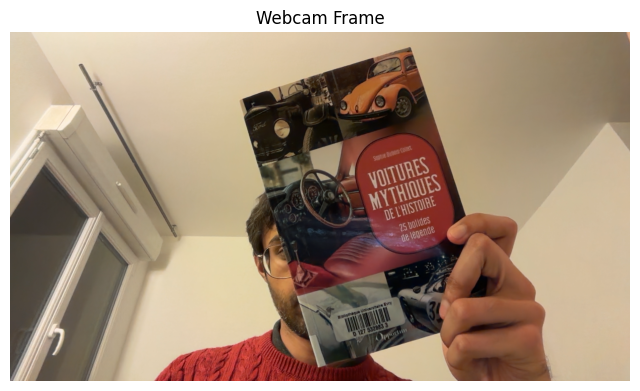

In [6]:
# Camera frame
if config.CAPTURE_NEW_FRAME:
    cv.imwrite(config.FRAME_PATH, grab_frame(config.CAMERA_INDEX))
frame = load_image(config.FRAME_PATH)
plot_image(frame, "Webcam Frame")

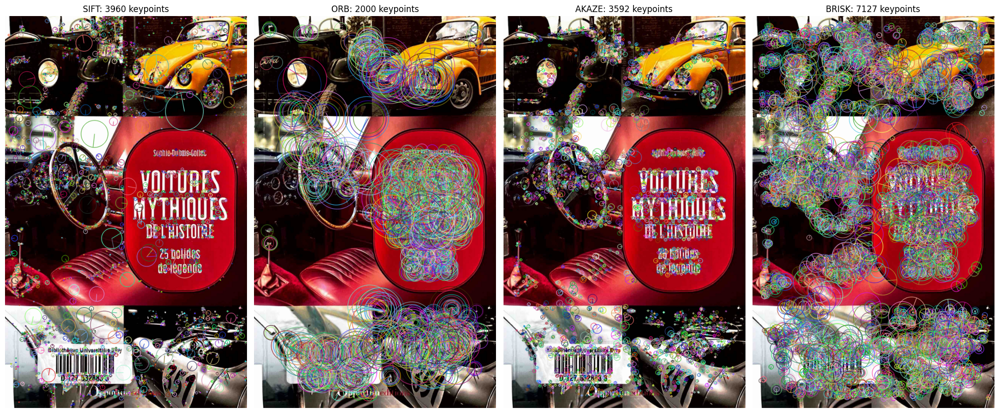

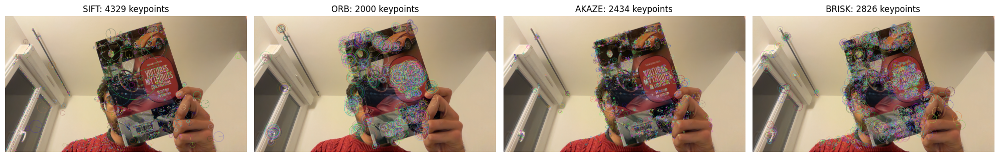

In [7]:
# Image descriptor extraction: every registered detector
marker_features = {}
frame_features = {}

marker_keypoint_images = []
marker_keypoint_titles = []
frame_keypoint_images = []
frame_keypoint_titles = []

for detector_name in config.DETECTORS:
    detector = build_detector(detector_name)

    # Marker keypoints
    marker_keypoints, marker_descriptors = apply_detector(detector, marker)
    marker_features[detector_name] = (marker_keypoints, marker_descriptors)
    marker_keypoint_images.append(draw_keypoints(marker, marker_keypoints))
    marker_keypoint_titles.append(f"{detector_name}: {len(marker_keypoints)} keypoints")

    # Frame keypoints
    frame_keypoints, frame_descriptors = apply_detector(detector, frame)
    frame_features[detector_name] = (frame_keypoints, frame_descriptors)
    frame_keypoint_images.append(draw_keypoints(frame, frame_keypoints))
    frame_keypoint_titles.append(f"{detector_name}: {len(frame_keypoints)} keypoints")

plot_image_row(marker_keypoint_images, marker_keypoint_titles)
plot_image_row(frame_keypoint_images, frame_keypoint_titles)

marker_keypoints, marker_descriptors = marker_features[config.DETECTOR_NAME]
frame_keypoints, frame_descriptors = frame_features[config.DETECTOR_NAME]

3960 marker descriptors matched


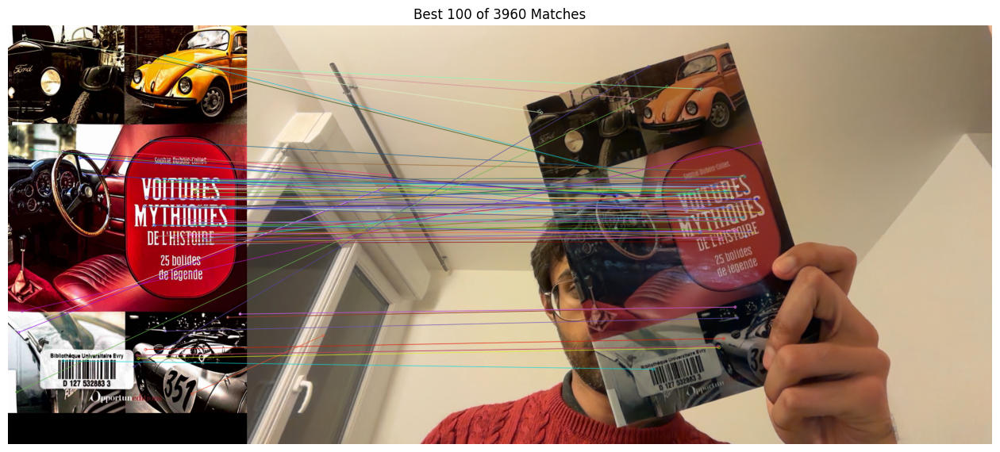

In [8]:
# Descriptor matching
matcher = build_matcher(config.MATCHER_NAME, config.DETECTOR_NAME)
knn_matches = apply_matcher(matcher, marker_descriptors, frame_descriptors)
print(f"{len(knn_matches)} marker descriptors matched")

# Plot only the closest matches
best_matches = select_best_matches(knn_matches)
shown_match_count = 100
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    best_matches[:shown_match_count],
    f"Best {shown_match_count} of {len(best_matches)} Matches",
)

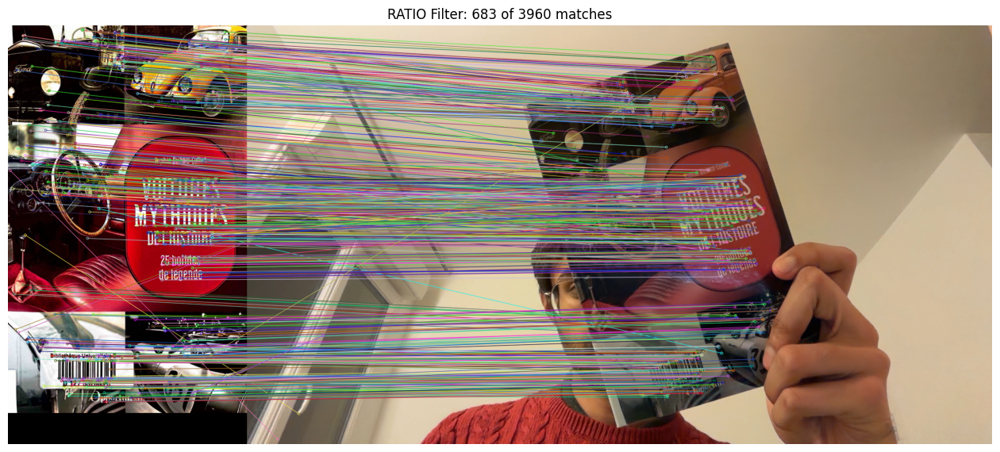

In [9]:
# Match filtering
match_filter = build_filter(config.FILTER_NAME)
filtered_matches = apply_filter(match_filter, knn_matches)
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    filtered_matches,
    f"{config.FILTER_NAME} Filter: {len(filtered_matches)} of {len(knn_matches)} matches",
)

RANSAC: 480 of 683 matches are inliers
LEAST_SQUARES: not found. The homography has 10 inliers at distinct train pixels, needs 15
LMEDS: 523 of 683 matches are inliers
PROSAC: 398 of 683 matches are inliers
[[ 8.41256621e-01  2.27781960e-01  7.09801219e+02]
 [-2.76327405e-01  8.09142608e-01  2.08695156e+02]
 [-2.70095426e-05 -1.79531127e-05  1.00000000e+00]]


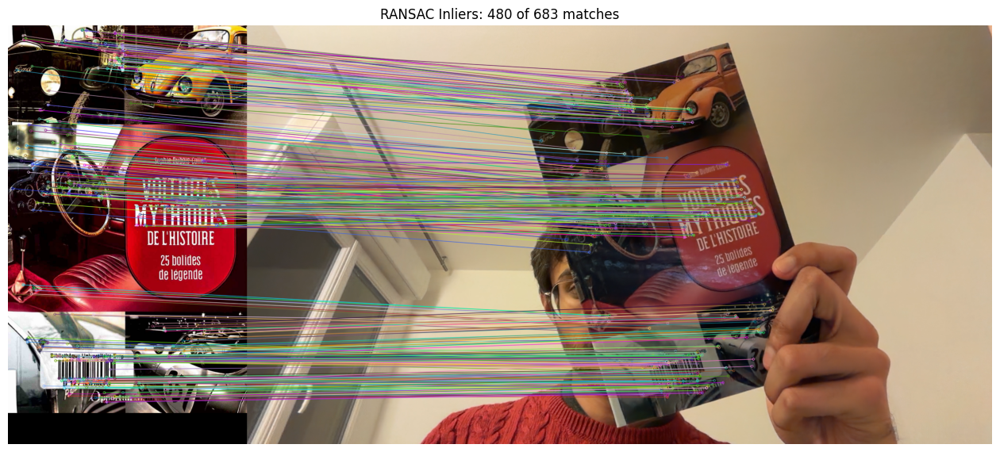

In [10]:
# Homography estimation: every registered estimator
homographies = {}
inlier_matches_by_estimator = {}

for estimator_name in config.ESTIMATORS:
    estimator = build_estimator(estimator_name)
    try:
        homography, inlier_mask = apply_estimator(
            estimator, marker_keypoints, frame_keypoints, filtered_matches
        )
    except HomographyNotFoundError as error:
        print(f"{estimator_name}: not found. {error}")
        continue

    inlier_matches = select_inlier_matches(filtered_matches, inlier_mask)
    homographies[estimator_name] = homography
    inlier_matches_by_estimator[estimator_name] = inlier_matches
    print(
        f"{estimator_name}: {len(inlier_matches)} of {len(filtered_matches)} matches are inliers"
    )

homography = homographies[config.ESTIMATOR_NAME]
inlier_matches = inlier_matches_by_estimator[config.ESTIMATOR_NAME]
print(homography)

# Plot only the matches that agree with the homography
plot_matches(
    marker,
    marker_keypoints,
    frame,
    frame_keypoints,
    inlier_matches,
    f"{config.ESTIMATOR_NAME} Inliers: {len(inlier_matches)} of {len(filtered_matches)} matches",
)

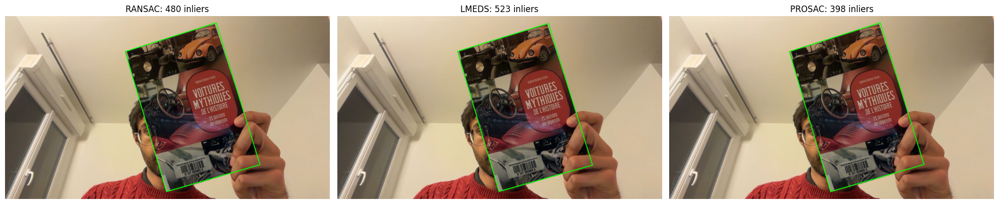

In [11]:
# Marker outline: every estimator that found a homography
outline_images = []
outline_titles = []

for estimator_name, estimator_homography in homographies.items():
    frame_corners = project_corners(estimator_homography, marker)
    outline_images.append(draw_outline(frame, frame_corners))
    inlier_count = len(inlier_matches_by_estimator[estimator_name])
    outline_titles.append(f"{estimator_name}: {inlier_count} inliers")

plot_image_row(outline_images, outline_titles)

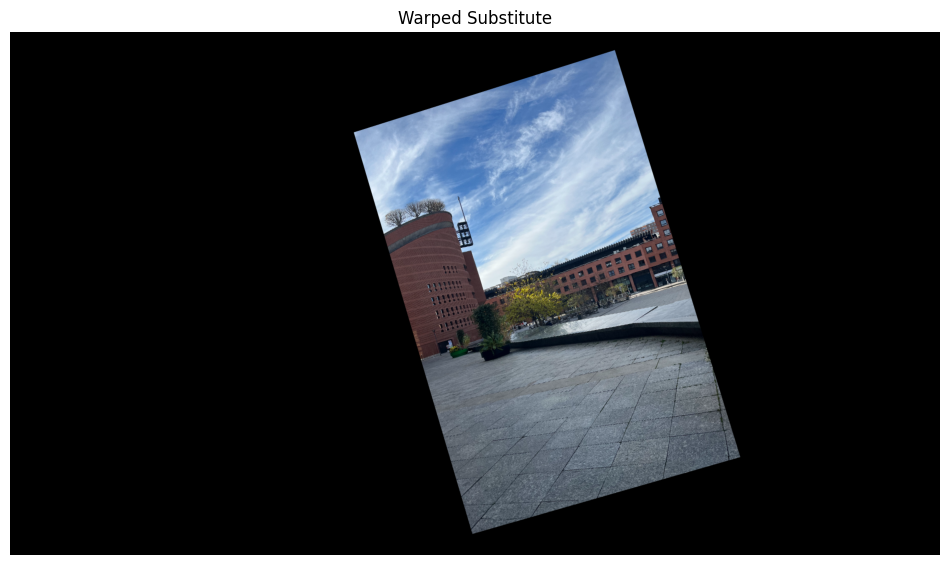

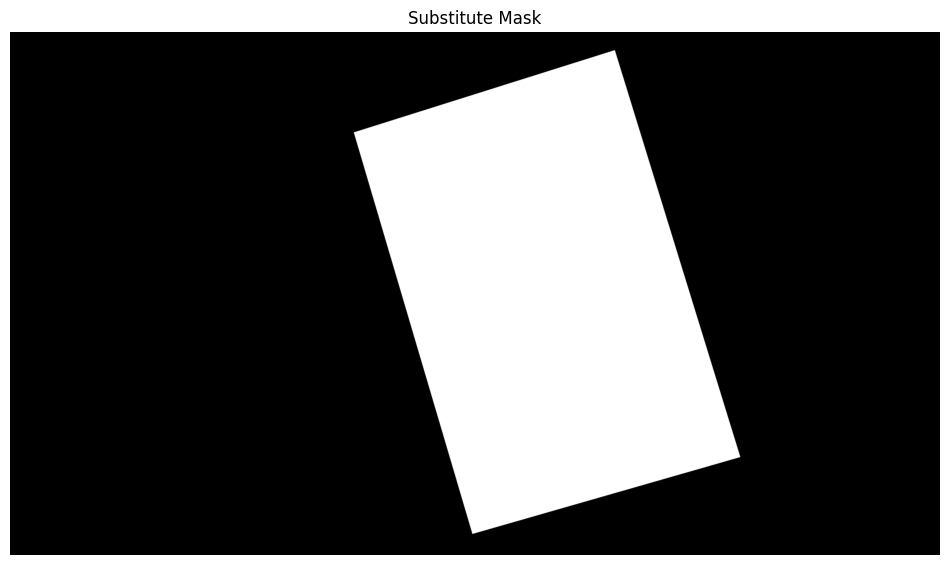

In [12]:
# Substitute warp
frame_height, frame_width = frame.shape[:2]
warped_substitute, substitute_mask = warp_image(
    substitute, homography, frame_width, frame_height
)
plot_image(warped_substitute, "Warped Substitute", 12)
plot_image(substitute_mask, "Substitute Mask", 12)

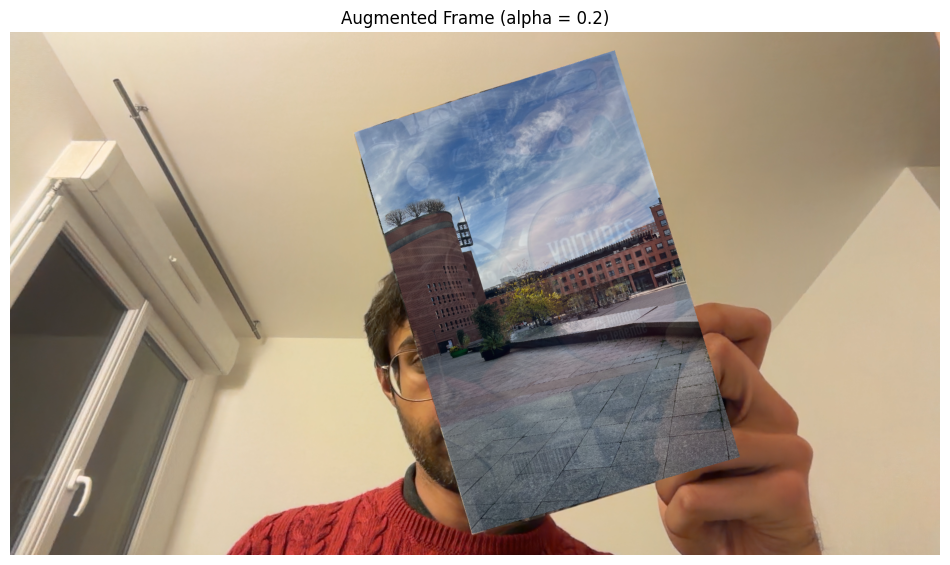

In [13]:
# Augmented frame
augmented_frame = overlay_image(
    frame, warped_substitute, substitute_mask, config.FRAME_ALPHA
)
plot_image(augmented_frame, f"Augmented Frame (alpha = {config.FRAME_ALPHA})", 12)

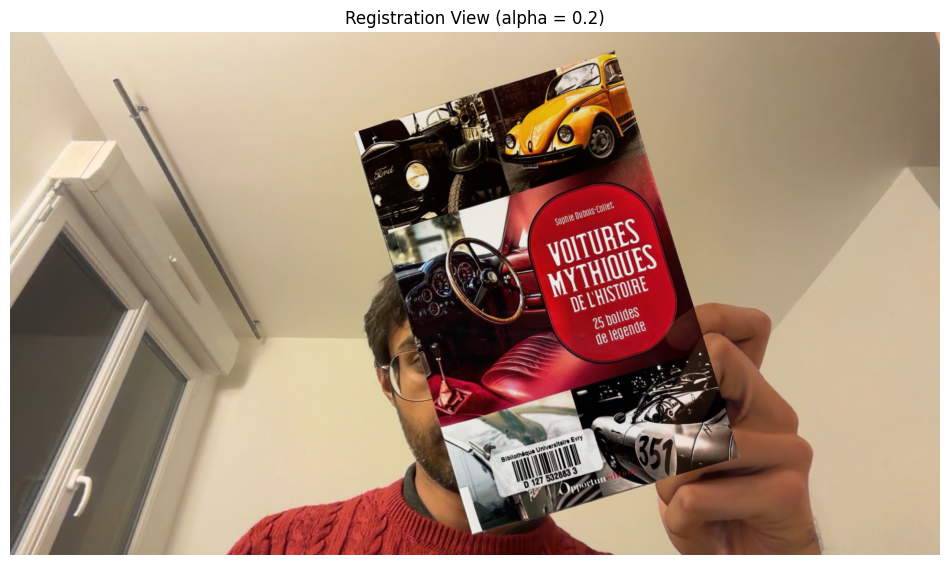

In [14]:
# Registration view: the marker itself warped onto the frame. If the
# homography is right, it lines up with the real marker (sharp, no ghosting)
warped_marker, marker_mask = warp_image(marker, homography, frame_width, frame_height)
registration_view = overlay_image(frame, warped_marker, marker_mask, config.FRAME_ALPHA)
plot_image(registration_view, f"Registration View (alpha = {config.FRAME_ALPHA})", 12)